In [1]:
!pip install matplotlib scikit-learn pandas numpy openpyxl seaborn scipy -q


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.optimize import linear_sum_assignment

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
dataset = r'C:\Users\rafaelmg\Downloads\algorithms-ML\main\dataset\Dataset-Sheet.xlsx'

categorias = ['planet', 'zodiac', 'element', 'yes_no', 'yes_no_reversed']
numericas = ['number_numerology']
texto = [
    'keywords_upright', 'keywords_reversed',
    'meaning_upright', 'meaning_reversed',
    'love', 'love_reversed',
    'career', 'career_reversed',
    'mood', 'mood_reversed',
    'spiritual', 'spiritual_reversed',
]

df = pd.read_excel(dataset)
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

y = df['suit'].mask(df['arcana'] == 'major', 'major')
n_classes = y.nunique()
print('Classes encontradas:', n_classes)
print(y.value_counts(), '\n')

def aggregate_col(valor):
    if isinstance(valor, list):
        return ' '.join(map(str, valor))
    if pd.isna(valor):
        return ''
    return str(valor)

X_df = pd.DataFrame(index=df.index)
for c in categorias:
    X_df[c] = df[c].fillna('desconhecido').astype(str)
for c in numericas:
    X_df[c] = pd.to_numeric(df[c], errors='coerce')
X_df['texto'] = df[texto].map(aggregate_col).agg(' '.join, axis=1)

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorias),
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('esc', StandardScaler()),
    ]), numericas),
    ('txt', TfidfVectorizer(
        stop_words='english', ngram_range=(1, 2),
        min_df=2, sublinear_tf=True, max_features=500,
    ), 'texto'),
])

X_sparse = pre.fit_transform(X_df)
print('Matriz de features (esparsa):', X_sparse.shape)

Classes encontradas: 5
suit
major        22
wands        14
cups         14
swords       14
pentacles    14
Name: count, dtype: int64 

Matriz de features (esparsa): (78, 538)


In [4]:
n_comp = 10
svd = TruncatedSVD(n_components=n_comp, random_state=42)
X_red = svd.fit_transform(X_sparse)
X_red = StandardScaler().fit_transform(X_red)

print('Componentes SVD:', n_comp)
print('Variancia explicada:', round(svd.explained_variance_ratio_.sum(), 4))
svd2 = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd2.fit_transform(X_sparse)
X_2d = StandardScaler().fit_transform(X_2d)

Componentes SVD: 10
Variancia explicada: 0.6491


In [5]:
kmeans = KMeans(n_clusters=n_classes, random_state=42, n_init=20)
labels_km = kmeans.fit_predict(X_red)

print('K-Means')
print('n_clusters usado :', n_classes)
print('Inercia          :', round(kmeans.inertia_, 2))
print('Silhouette score :', round(silhouette_score(X_red, labels_km), 4))
print('Distribuicao     :', pd.Series(labels_km).value_counts().sort_index().to_dict())

K-Means
n_clusters usado : 5
Inercia          : 489.05
Silhouette score : 0.1552
Distribuicao     : {0: 17, 1: 20, 2: 15, 3: 11, 4: 15}


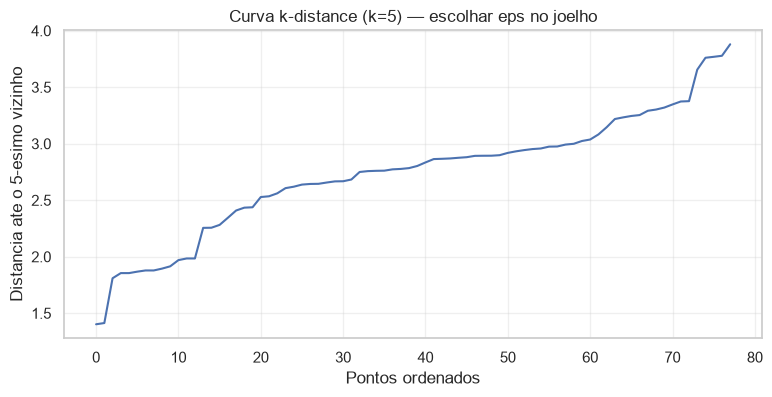

eps=2.793 -> clusters=2, ruido=23.1%

DBSCAN escolhido -> eps=2.793, min_samples=5
Clusters encontrados : 2
Ruido (-1)           : 23.1%
Distribuicao         : {-1: 18, 0: 45, 1: 15}


In [6]:
k = 5
nn = NearestNeighbors(n_neighbors=k).fit(X_red)
distancias, _ = nn.kneighbors(X_red)
dist_k = np.sort(distancias[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(dist_k)
plt.title('Curva k-distance (k=5) — escolhar eps no joelho')
plt.xlabel('Pontos ordenados')
plt.ylabel(f'Distancia ate o {k}-esimo vizinho')
plt.grid(alpha=.3)
plt.show()

candidatos = np.linspace(np.percentile(dist_k, 50), np.percentile(dist_k, 95), 10)
labels_db = None
eps_escolhido = None
for eps in candidatos:
    lab = DBSCAN(eps=eps, min_samples=k).fit_predict(X_red)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    ruido = (lab == -1).mean()
    print(f'eps={eps:.3f} -> clusters={n_cl}, ruido={ruido:.1%}')
    if 2 <= n_cl <= 10 and ruido < 0.40:
        labels_db = lab
        eps_escolhido = eps
        break

if labels_db is None:
    eps_escolhido = candidatos[0]
    labels_db = DBSCAN(eps=eps_escolhido, min_samples=k).fit_predict(X_red)

n_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print(f'\nDBSCAN escolhido -> eps={eps_escolhido:.3f}, min_samples={k}')
print('Clusters encontrados :', n_db)
print('Ruido (-1)           :', f'{(labels_db == -1).mean():.1%}')
print('Distribuicao         :', pd.Series(labels_db).value_counts().sort_index().to_dict())

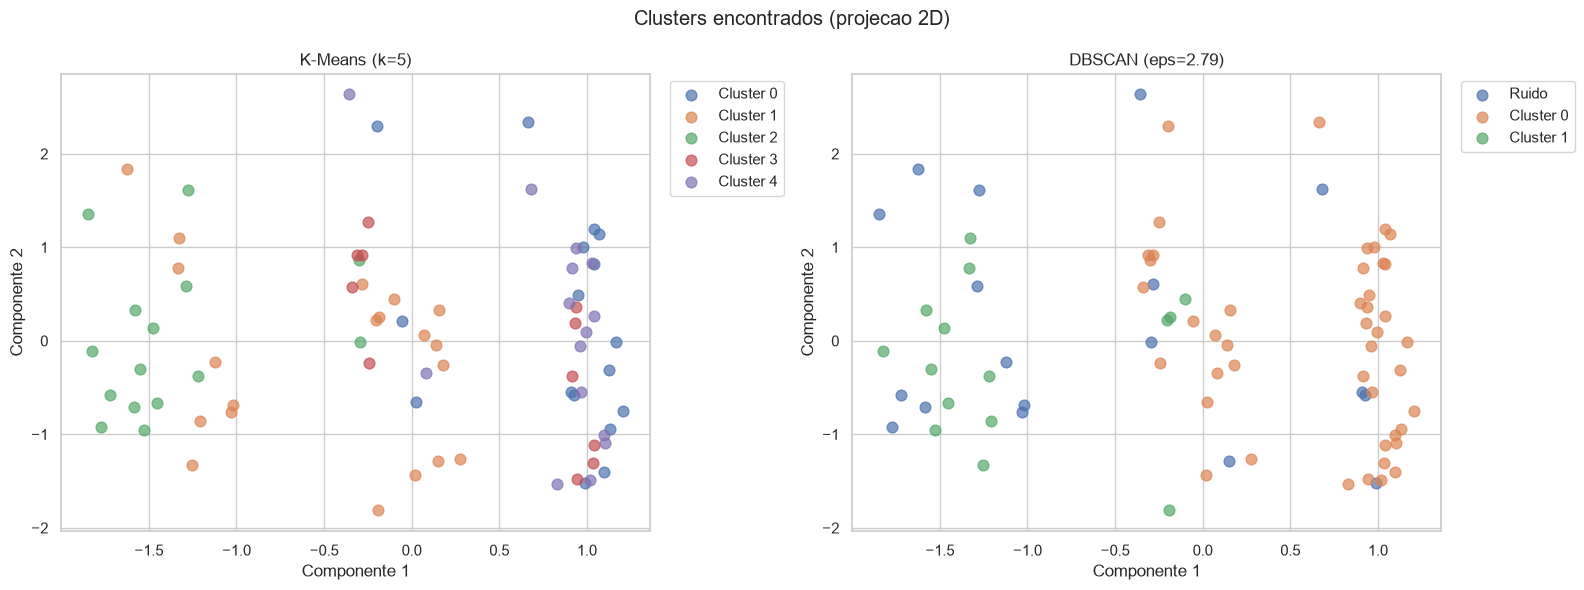

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, labels, titulo in [
    (axes[0], labels_km, f'K-Means (k={n_classes})'),
    (axes[1], labels_db, f'DBSCAN (eps={eps_escolhido:.2f})'),
]:
    for cl in sorted(set(labels)):
        mask = labels == cl
        nome = 'Ruido' if cl == -1 else f'Cluster {cl}'
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1], label=nome, s=60, alpha=.7)
    ax.set_title(titulo)
    ax.set_xlabel('Componente 1')
    ax.set_ylabel('Componente 2')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle('Clusters encontrados (projecao 2D)')
plt.tight_layout()
plt.show()

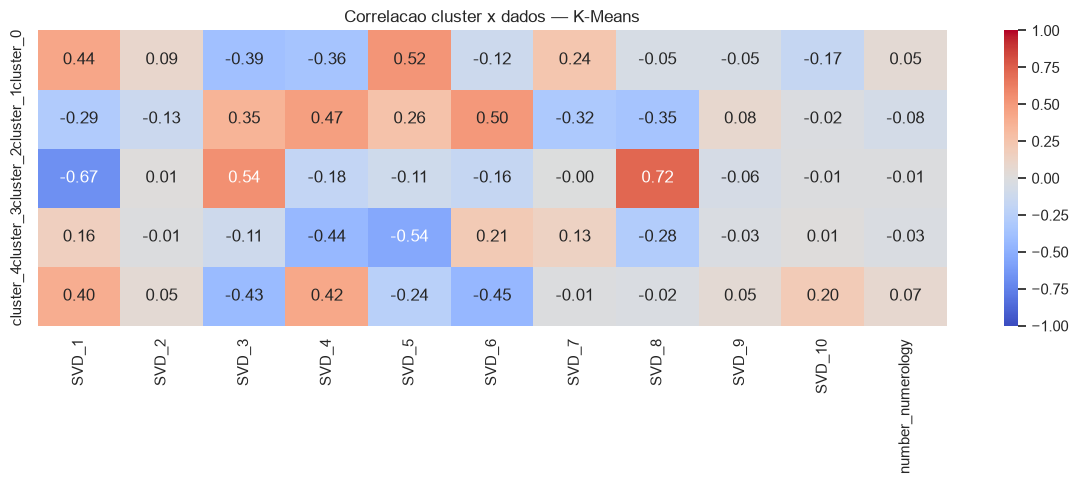

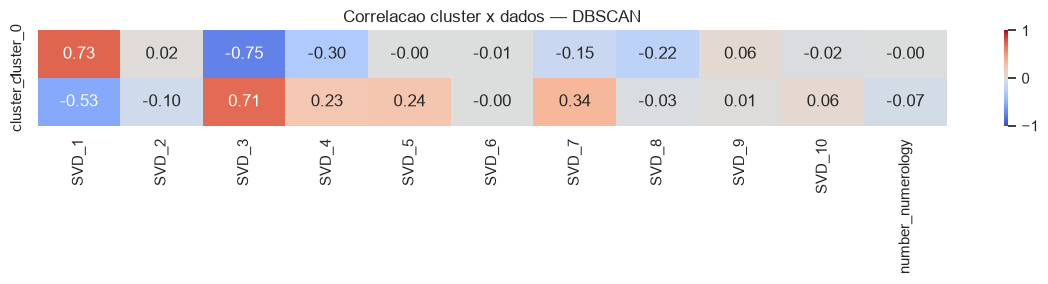

In [8]:
def heatmap_cluster_dados(labels, nome):
    clusters_validos = sorted(set(labels) - {-1})
    dummies = pd.DataFrame({
        f'cluster_{c}': (labels == c).astype(int) for c in clusters_validos
    }, index=df.index)

    dados = pd.DataFrame(X_red, columns=[f'SVD_{i+1}' for i in range(n_comp)])
    dados['number_numerology'] = X_df['number_numerology'].values

    corr = pd.concat([dummies, dados], axis=1).corr()
    bloco = corr.loc[dummies.columns, dados.columns]

    plt.figure(figsize=(12, max(3, len(clusters_validos))))
    sns.heatmap(bloco, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
    plt.title(f'Correlacao cluster x dados — {nome}')
    plt.tight_layout()
    plt.show()

heatmap_cluster_dados(labels_km, 'K-Means')
heatmap_cluster_dados(labels_db, 'DBSCAN')

===== K-Means =====
Contagem cluster x classe:
classe   cups  major  pentacles  swords  wands
cluster                                       
0           0      7          0       1      9
1           1      8          2       6      3
2           3      3          1       6      2
3          10      1          0       0      0
4           0      3         11       1      0 

Percentual por cluster (linha = 100%):
classe    cups  major pentacles swords  wands
cluster                                      
0         0.0%  41.2%      0.0%   5.9%  52.9%
1         5.0%  40.0%     10.0%  30.0%  15.0%
2        20.0%  20.0%      6.7%  40.0%  13.3%
3        90.9%   9.1%      0.0%   0.0%   0.0%
4         0.0%  20.0%     73.3%   6.7%   0.0% 

Melhor correspondencia cluster -> classe (assignment otimo):
  cluster 0 -> wands (9 cartas, 53% do cluster)
  cluster 1 -> major (8 cartas, 40% do cluster)
  cluster 2 -> swords (6 cartas, 40% do cluster)
  cluster 3 -> cups (10 cartas, 91% do cluster)
  clu

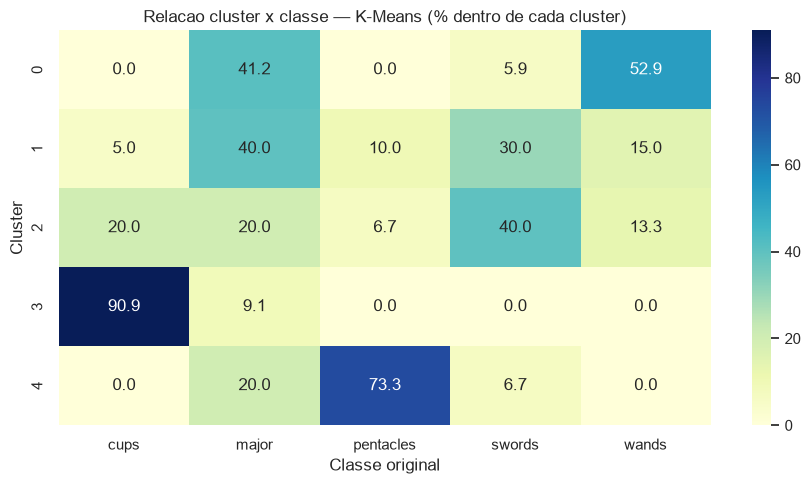

===== DBSCAN =====
Contagem cluster x classe:
classe   cups  major  pentacles  swords  wands
cluster                                       
-1          4      9          3       1      1
 0         10     11         11       1     12
 1          0      2          0      12      1 

Percentual por cluster (linha = 100%):
classe    cups  major pentacles swords  wands
cluster                                      
-1       22.2%  50.0%     16.7%   5.6%   5.6%
 0       22.2%  24.4%     24.4%   2.2%  26.7%
 1        0.0%  13.3%      0.0%  80.0%   6.7% 

Melhor correspondencia cluster -> classe (assignment otimo):
  cluster 0 -> wands (12 cartas, 27% do cluster)
  cluster 1 -> swords (12 cartas, 80% do cluster)
Acuracia de correspondencia: 40.00% (sobre 60 cartas nao-ruido)
Adjusted Rand Index vs classes: 0.160


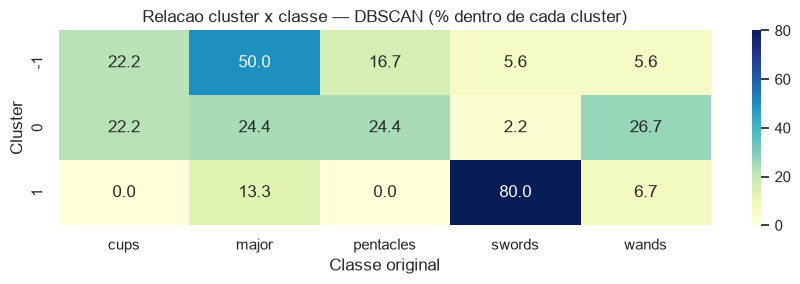

classe,cups,major,pentacles,swords,wands
cluster,,,,,
-1,4,9,3,1,1
0,10,11,11,1,12
1,0,2,0,12,1


In [9]:
def analise_clusters_classes(labels, nome):
    labels_s = pd.Series(labels, name='cluster')
    y_s = pd.Series(y.values, name='classe')
    tabela = pd.crosstab(labels_s, y_s)
    pct = tabela.div(tabela.sum(axis=1), axis=0) * 100

    print(f'===== {nome} =====')
    print('Contagem cluster x classe:')
    print(tabela.to_string(), '\n')
    print('Percentual por cluster (linha = 100%):')
    print((pct.round(1).astype(str) + '%').to_string(), '\n')

    clusters_validos = sorted(set(labels) - {-1})
    classes = sorted(y_s.unique())
    M = tabela.reindex(index=clusters_validos, columns=classes,
                       fill_value=0).values
    ri, ci = linear_sum_assignment(-M)
    acertos = M[ri, ci].sum()
    total = labels_s[labels_s != -1].shape[0]

    print('Melhor correspondencia cluster -> classe (assignment otimo):')
    for r, c in zip(ri, ci):
        print(f'  cluster {clusters_validos[r]} -> {classes[c]} ' f'({M[r, c]} cartas, {M[r, c] / max(M[r].sum(), 1):.0%} do cluster)')
    print(f'Acuracia de correspondencia: {acertos / total:.2%} 'f'(sobre {total} cartas nao-ruido)')
    print(f'Adjusted Rand Index vs classes: 'f'{adjusted_rand_score(y_s[labels_s != -1], labels_s[labels_s != -1]):.3f}')
    plt.figure(figsize=(9, max(3, len(clusters_validos))))
    sns.heatmap(pct, annot=True, fmt='.1f', cmap='YlGnBu')
    plt.title(f'Relacao cluster x classe — {nome} (% dentro de cada cluster)')
    plt.ylabel('Cluster')
    plt.xlabel('Classe original')
    plt.tight_layout()
    plt.show()
    return tabela

analise_clusters_classes(labels_km, 'K-Means')
analise_clusters_classes(labels_db, 'DBSCAN')